# 04 · What did the agent learn?

The agent was never shown a strategy, only wins and losses. Here it is compared with the strategies it trained against: does it play like one of them, or has it found something of its own?

Data: `results/improvements.json`, `results/lookahead.json`, `results/evaluation.json`, `results/style.json`, `results/raw/agent_games.parquet` (`python -m catanbot.pipeline improvements|lookahead|agent --checkpoint ...`).

Everything after the first section is the final agent: the network after both training phases, playing with look-ahead.

In [1]:
import json
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"balanced": "#2a6f97", "ows": "#7d5ba6", "road_builder": "#b5532f", "dev_rush": "#3c8d5a",
          "port_master": "#c9962b", "greedy": "#8a8f98", "random": "#b8bcc4", "learned": "#d1495b"}
LABELS = {"balanced": "Balanced", "ows": "Ore-Wheat-Sheep", "road_builder": "Road Builder",
          "dev_rush": "Dev-Card Rush", "port_master": "Port Master", "learned": "Learned (RL)"}

ev = json.loads((RESULTS / 'evaluation.json').read_text())
style = json.loads((RESULTS / 'style.json').read_text())
agent = pl.read_parquet(RESULTS / 'raw' / 'agent_games.parquet')
bots = pl.read_parquet(RESULTS / 'raw' / 'tournament.parquet')

## Making it stronger, step by step
The first agent fell short of the tuned Balanced bot. Two changes followed: a second training phase with most opponent seats
given to the strategy bots, and a decision-time look-ahead (each plausible move is played to the agent's next turn in 16
imagined futures, with hidden cards re-dealt and the dice re-seeded, and scored by the agent's value network). Every step
below plays the same games, on seeds the look-ahead settings were never tuned on.

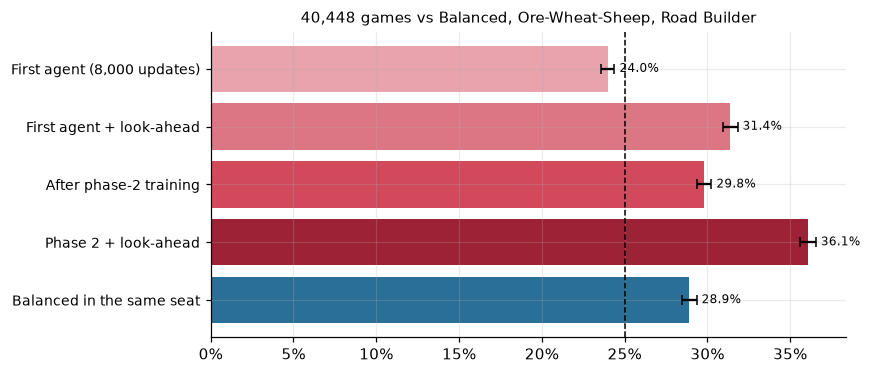

In [2]:
imp = json.loads((RESULTS / 'improvements.json').read_text())
STEP_COLORS = {'phase1': '#e8a3ad', 'phase1_lookahead': '#dd7684', 'phase2': '#d1495b', 'phase2_lookahead': '#9e2235'}
base = imp['baseline']
steps = imp['steps'] + [{**base, 'key': base['bot'], 'label': f"{LABELS[base['bot']]} in the same seat"}]
fig, ax = plt.subplots(figsize=(8, 0.5 * len(steps) + 1))
y = np.arange(len(steps))[::-1]
ax.barh(y, [s['win_rate'] for s in steps], color=[STEP_COLORS.get(s['key'], COLORS.get(s['key'])) for s in steps],
        xerr=[[s['win_rate'] - s['ci_low'] for s in steps], [s['ci_high'] - s['win_rate'] for s in steps]], capsize=3)
for yi, s in zip(y, steps):
    ax.text(s['ci_high'] + 0.003, yi, f"{s['win_rate']:.1%}", va='center', fontsize=8)
ax.set_yticks(y, [s['label'] for s in steps], fontsize=9)
ax.axvline(0.25, color='k', ls='--', lw=1); ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_title(f"{imp['steps'][0]['games']:,} games vs {', '.join(LABELS[t] for t in imp['table'])}", fontsize=10)
plt.tight_layout(); plt.show()

### Choosing the look-ahead settings
Tuned on different seeds (`pipeline lookahead`) with the first agent. The first version scored each candidate at the
agent's very next decision, which compares positions taken at different moments; playing every candidate to the same
point (the agent's next turn) is what made it work.

In [3]:
las = json.loads((RESULTS / 'lookahead.json').read_text())
pl.DataFrame([{'variant': v['label'], 'games': v['games'], 'win rate': round(v['win_rate'], 4),
               'ci': f"{v['ci_low']:.1%}-{v['ci_high']:.1%}", 'moves changed': v['lookahead'].get('changed_frac'),
               'minutes': round(v['seconds'] / 60, 1)} for v in las['variants']])

variant,games,win rate,ci,moves changed,minutes
str,i64,f64,str,f64,f64
"""Policy alone""",8192,0.2394,"""23.0%-24.9%""",null,1.3
"""Score at the next decision""",8192,0.2434,"""23.4%-25.3%""",0.09243,4.4
"""Next decision, 48 futures per …",8192,0.2466,"""23.7%-25.6%""",0.092897,9.4
"""Next decision, clear gains onl…",8192,0.2526,"""24.3%-26.2%""",0.035218,4.7
"""Score at the next turn (unsure…",8192,0.2863,"""27.7%-29.6%""",0.078132,18.3
"""Next turn, every plausible dec…",8192,0.2988,"""28.9%-30.9%""",0.115975,7.4
"""Next turn, wider shortlist (fi…",8192,0.3085,"""29.9%-31.9%""",0.15169,13.3


## Final evaluation
The final agent in one seat and three tuned strategy bots in the others, all seats rotated. The baseline is the strongest strategy bot sitting in the agent's seat against the same opponents.

In [4]:
rows = [{'opponents': ', '.join(LABELS[t] for t in e['table']), 'games': e['games'], 'agent': e['win_rate'],
         'ci': f"{e['ci_low']:.1%}-{e['ci_high']:.1%}", 'baseline bot': LABELS[e['baseline']['bot']],
         'baseline': e['baseline']['win_rate']} for e in ev]
pl.DataFrame(rows)

opponents,games,agent,ci,baseline bot,baseline
str,i64,f64,str,str,f64
"""Balanced, Ore-Wheat-Sheep, Roa…",40448,0.360883,"""35.6%-36.6%""","""Balanced""",0.289075
"""Balanced, Ore-Wheat-Sheep, Dev…",4096,0.35376,"""33.9%-36.9%""","""Balanced""",0.35775
"""Balanced, Ore-Wheat-Sheep, Por…",4096,0.34375,"""32.9%-35.8%""","""Balanced""",0.32675
"""Balanced, Road Builder, Dev-Ca…",4096,0.349854,"""33.5%-36.5%""","""Balanced""",0.3035
"""Balanced, Road Builder, Port M…",4096,0.431396,"""41.6%-44.7%""","""Balanced""",0.33975
"""Balanced, Dev-Card Rush, Port …",4096,0.369141,"""35.4%-38.4%""","""Balanced""",0.34725
"""Ore-Wheat-Sheep, Road Builder,…",4096,0.35791,"""34.3%-37.3%""","""Balanced""",0.33625
"""Ore-Wheat-Sheep, Road Builder,…",4096,0.420166,"""40.5%-43.5%""","""Balanced""",0.35325
"""Ore-Wheat-Sheep, Dev-Card Rush…",4096,0.427979,"""41.3%-44.3%""","""Balanced""",0.44475


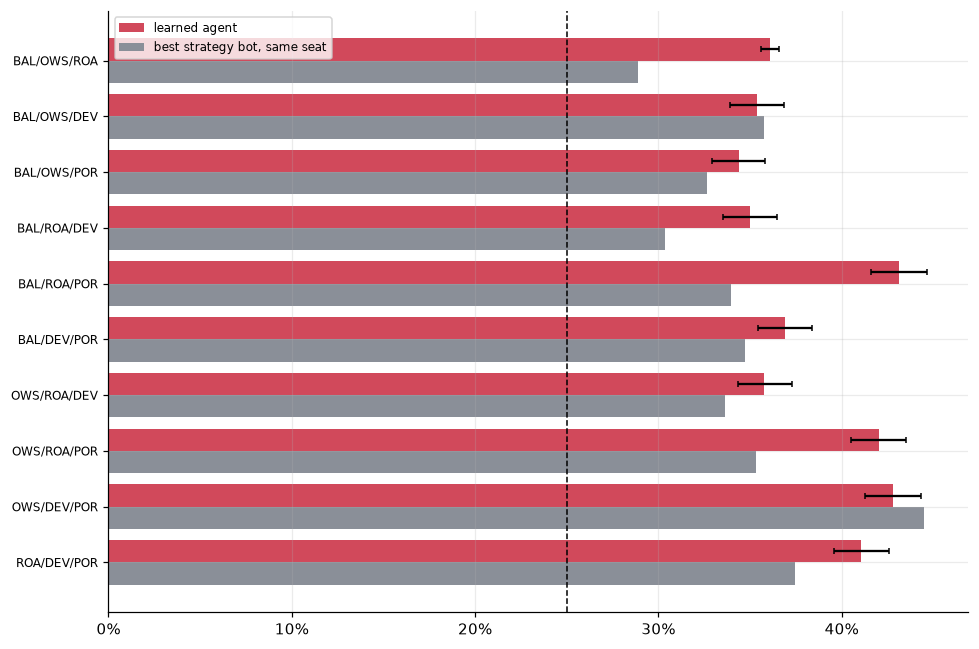

In [5]:
fig, ax = plt.subplots(figsize=(9, 0.5 * len(ev) + 1))
y = np.arange(len(ev))[::-1]
ax.barh(y + 0.2, [e['win_rate'] for e in ev], 0.4, color=COLORS['learned'], label='learned agent',
        xerr=[[e['win_rate'] - e['ci_low'] for e in ev], [e['ci_high'] - e['win_rate'] for e in ev]], capsize=2)
ax.barh(y - 0.2, [e['baseline']['win_rate'] for e in ev], 0.4, color='#8a8f98', label='best strategy bot, same seat')
ax.set_yticks(y, ['/'.join(t[:3].upper() for t in e['table']) for e in ev], fontsize=8)
ax.axvline(0.25, color='k', ls='--', lw=1); ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Play style vs. the strategies

In [6]:
pl.DataFrame(style['rows'], infer_schema_length=None)

bot,win_rate,opening_ore_wheat,opening_wood_brick,opening_port,settlements,cities,roads,dev_bought,trades,longest_road,largest_army,first_city_turn
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""learned""",0.363403,0.490991,0.298275,0.109253,1.424927,1.78894,5.813843,7.553223,5.568237,0.074219,0.575562,32.455109
"""balanced""",0.376428,0.398497,0.425339,0.202191,3.163274,1.898075,8.796728,1.730917,6.559163,0.289945,0.02995,42.119604
"""ows""",0.28659,0.669841,0.156512,0.236627,0.562759,2.486472,4.375959,5.938284,6.381954,0.012334,0.362316,23.843168
"""road_builder""",0.229294,0.171754,0.67812,0.208683,3.955308,0.912561,9.625185,0.777652,6.399954,0.71464,0.004061,56.421727
"""dev_rush""",0.202587,0.497332,0.127196,0.228221,0.771922,1.688041,3.207097,7.812136,6.487654,0.00161,0.615478,29.557204
"""port_master""",0.155141,0.33666,0.431129,0.667541,3.034597,1.471939,7.759123,0.943674,9.127432,0.18968,0.009382,43.769747


## Opening choices
Production (in pips) per resource right after the two setup settlements.

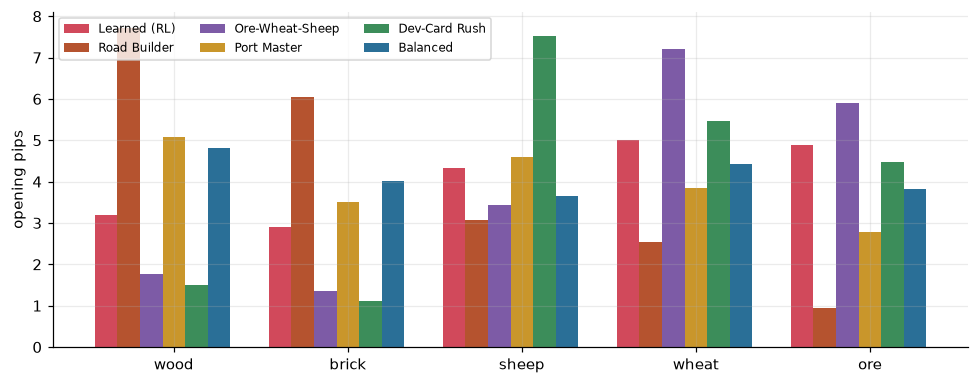

In [7]:
res = ['wood', 'brick', 'sheep', 'wheat', 'ore']
def opening(df):
    o = df.group_by('bot').agg([pl.col(f'opening_{r}').mean().alias(r) for r in res])
    return o
o = pl.concat([opening(agent.filter(pl.col('bot') == 'learned')), opening(bots)])
fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.13
for i, r in enumerate(o.iter_rows(named=True)):
    ax.bar(np.arange(5) + (i - len(o) / 2) * w, [r[x] for x in res], w, label=LABELS.get(r['bot'], r['bot']), color=COLORS.get(r['bot']))
ax.set_xticks(range(5), res); ax.set_ylabel('opening pips'); ax.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

## Does the agent adapt its plan to the board?
If the agent follows one fixed strategy, its opening resource mix should barely vary. If it adapts, the mix should follow what the board offers. Below: the distribution of the ore+wheat share of the agent's opening production, compared with Ore-Wheat-Sheep and Road Builder.

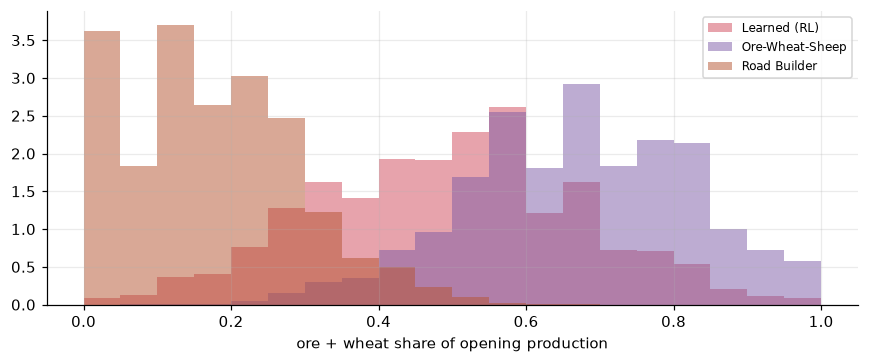

In [8]:
def share(df):
    tot = sum(pl.col(f'opening_{r}') for r in res)
    return df.with_columns(((pl.col('opening_ore') + pl.col('opening_wheat')) / tot).alias('ow'))
fig, ax = plt.subplots(figsize=(8, 3.4))
for name, d in [('learned', share(agent.filter(pl.col('bot') == 'learned'))), ('ows', share(bots.filter(pl.col('bot') == 'ows'))),
                ('road_builder', share(bots.filter(pl.col('bot') == 'road_builder')))]:
    ax.hist(d['ow'].drop_nulls().to_numpy(), bins=20, range=(0, 1), alpha=0.5, density=True, label=LABELS[name], color=COLORS[name])
ax.set_xlabel('ore + wheat share of opening production'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## How the agent's wins are built

In [9]:
aw = agent.filter((pl.col('bot') == 'learned') & (pl.col('won') == 1))
aw.select([pl.col('settlements').mean(), (2 * pl.col('cities')).mean().alias('city VP'),
           (2 * pl.col('longest_road')).mean().alias('LR VP'), (2 * pl.col('largest_army')).mean().alias('LA VP'),
           pl.col('vp_cards').mean(), pl.col('dev_bought').mean(), pl.col('trades').mean(), pl.col('turns').mean()])

settlements,city VP,LR VP,LA VP,vp_cards,dev_bought,trades,turns
f64,f64,f64,f64,f64,f64,f64,f64
1.374538,4.770574,0.302318,1.620423,1.988579,8.776285,6.202553,74.997649
